# BLS QCEW - Business Establishments, Employment, and Wages

The purpose of this notebook is to inspect, validate, and prepare annual QCEW data for the 50 US states from 2014 to 2025, focusing on economic indicators relevant to documented cybersecurity incidents.

## 1. Data source and scope

**Source:** [BLS Quarterly Census of Employment and Wages (QCEW)](https://www.bls.gov/cew/downloadable-data-files.htm)

**Files:** Annual *by area* CSV archives for 2014–2025.

The QCEW program reports establishments, employment, and wages for covered jobs. Source records distinguish geographic areas, industry classifications, and ownership categories; their exact keys and aggregation levels will be verified before processing.

In [1]:

from pathlib import Path
from zipfile import ZipFile
import sys

import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

PROJECT_ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(PROJECT_ROOT / "src" / "data_processing"))

from qcew_io import load_qcew_states



### 1.1 Available annual archives

Annual QCEW archives are inspected to verify their availability and internal structure before selecting the relevant geographic and industry records.


In [2]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]
QCEW_DIR = PROJECT_ROOT / "data" / "raw" / "bls" / "qcew"

archive_overview = []

for year in range(2014, 2026):
    path = QCEW_DIR / f"{year}_annual_by_area.zip"

    if path.exists():
        with ZipFile(path) as archive:
            csv_files = [
                name for name in archive.namelist()
                if name.lower().endswith(".csv")
            ]

        archive_overview.append({
            "year": year,
            "size_mb": round(path.stat().st_size / 1024**2, 2),
            "csv_files": len(csv_files),
            "example_file": csv_files[0] if csv_files else None
        })
    else:
        archive_overview.append({
            "year": year,
            "size_mb": None,
            "csv_files": 0,
            "example_file": None
        })

display(pd.DataFrame(archive_overview))


,year,size_mb,csv_files,example_file
0,2014,122.32,4426,2014.annual.by_area/2014.annual 01000 Alabama ...
1,2015,119.25,4429,2015.annual.by_area/2015.annual 01000 Alabama ...
2,2016,129.42,4426,2016.annual.by_area/2016.annual 01000 Alabama ...
3,2017,126.38,4427,2017.annual.by_area/2017.annual 01000 Alabama ...
4,2018,129.88,4428,2018.annual.by_area/2018.annual 01000 Alabama ...
5,2019,130.50,4428,2019.annual.by_area/2019.annual 01000 Alabama ...
6,2020,128.90,4429,2020.annual.by_area/2020.annual 01000 Alabama ...
7,2021,132.05,4429,2021.annual.by_area/2021.annual 01000 Alabama ...
8,2022,131.68,4429,2022.annual.by_area/2022.annual 01000 Alabama ...
9,2023,139.43,4429,2023.annual.by_area/2023.annual 01000 Alabama ...


## 2. Data overview

The annual archives contain separate CSV files for geographic areas. State-level files are examined to identify the available indicators, industry classifications, and ownership categories.

### 2.1 Dataset structure

The 2025 Alabama file is used to inspect the structure before processing all states and years.


In [3]:
# Read the Alabama state-level file directly from the 2025 archive
archive_path = QCEW_DIR / "2025_annual_by_area.zip"

with ZipFile(archive_path) as archive:
    matches = [
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
        and "01000 Alabama" in name
    ]

    print("Matching files:", matches)

    assert len(matches) == 1, "Expected exactly one Alabama state file"

    with archive.open(matches[0]) as file:
        qcew_sample = pd.read_csv(file, low_memory=False)

print("Rows:", len(qcew_sample))
print("Columns:", len(qcew_sample.columns))
print("Column names:")
print(qcew_sample.columns.tolist())

display(qcew_sample.head(5))


Matching files: ['2025.annual.by_area/2025.annual 01000 Alabama -- Statewide.csv']
Rows: 2854
Columns: 43
Column names:
['area_fips', 'own_code', 'industry_code', 'agglvl_code', 'size_code', 'year', 'qtr', 'disclosure_code', 'area_title', 'own_title', 'industry_title', 'agglvl_title', 'size_title', 'annual_avg_estabs_count', 'annual_avg_emplvl', 'total_annual_wages', 'taxable_annual_wages', 'annual_contributions', 'annual_avg_wkly_wage', 'avg_annual_pay', 'lq_disclosure_code', 'lq_annual_avg_estabs_count', 'lq_annual_avg_emplvl', 'lq_total_annual_wages', 'lq_taxable_annual_wages', 'lq_annual_contributions', 'lq_annual_avg_wkly_wage', 'lq_avg_annual_pay', 'oty_disclosure_code', 'oty_annual_avg_estabs_count_chg', 'oty_annual_avg_estabs_count_pct_chg', 'oty_annual_avg_emplvl_chg', 'oty_annual_avg_emplvl_pct_chg', 'oty_total_annual_wages_chg', 'oty_total_annual_wages_pct_chg', 'oty_taxable_annual_wages_chg', 'oty_taxable_annual_wages_pct_chg', 'oty_annual_contributions_chg', 'oty_annual_co

,area_fips,own_code,industry_code,agglvl_code,size_code,year,qtr,disclosure_code,area_title,own_title,...,oty_total_annual_wages_chg,oty_total_annual_wages_pct_chg,oty_taxable_annual_wages_chg,oty_taxable_annual_wages_pct_chg,oty_annual_contributions_chg,oty_annual_contributions_pct_chg,oty_annual_avg_wkly_wage_chg,oty_annual_avg_wkly_wage_pct_chg,oty_avg_annual_pay_chg,oty_avg_annual_pay_pct_chg
0,1000,0,10,50,0,2025,A,NaN,Alabama -- Statewide,Total Covered,...,5977419925,4.6,38718930,0.2,-12580563,-14.1,47,3.9,2435,3.9
1,1000,1,10,51,0,2025,A,NaN,Alabama -- Statewide,Federal Government,...,91127383,1.6,0,0.0,0,0.0,78,4.0,4046,4.0
2,1000,1,101,52,0,2025,A,NaN,Alabama -- Statewide,Federal Government,...,109786,189.0,0,0.0,0,0.0,447,30.0,23262,30.0
3,1000,1,1013,53,0,2025,A,NaN,Alabama -- Statewide,Federal Government,...,109786,189.0,0,0.0,0,0.0,447,30.0,23262,30.0
4,1000,1,102,52,0,2025,A,NaN,Alabama -- Statewide,Federal Government,...,91017597,1.6,0,0.0,0,0.0,78,4.0,4046,4.0


### 2.2 Selected indicators and aggregation levels

The analysis focuses on business establishments, employment, and wages at the state and major-industry levels.

Ownership and industry aggregation codes are examined to avoid double-counting overlapping records. Detailed industries and unrelated wage measures are excluded.


In [4]:
# Inspect ownership and industry aggregation categories
category_overview = (
    qcew_sample[
        ["own_code", "own_title", "agglvl_code", "agglvl_title"]
    ]
    .drop_duplicates()
    .sort_values(["own_code", "agglvl_code"])
    .reset_index(drop=True)
)

display(category_overview)


,own_code,own_title,agglvl_code,agglvl_title
0,0,Total Covered,50,"State, Total Covered"
1,1,Federal Government,51,"State, Total -- by ownership sector"
2,1,Federal Government,52,"State, by Domain -- by ownership sector"
3,1,Federal Government,53,"State, by Supersector -- by ownership sector"
4,1,Federal Government,54,"State, NAICS Sector -- by ownership sector"
5,1,Federal Government,55,"State, NAICS 3-digit -- by ownership sector"
6,1,Federal Government,56,"State, NAICS 4-digit -- by ownership sector"
7,1,Federal Government,57,"State, NAICS 5-digit -- by ownership sector"
8,1,Federal Government,58,"State, NAICS 6-digit -- by ownership sector"
9,2,State Government,51,"State, Total -- by ownership sector"


### 2.3 Industry selection

State-level totals and major NAICS industries are selected separately to prevent double-counting. Private-sector industry records are initially examined at the two-digit NAICS level, while government employment is treated as a separate ownership category.

The final industry selection will prioritize sectors relevant to cybersecurity incidents and comparability with the BEA dataset.


In [5]:
# Inspect major NAICS industries in the private sector
industry_overview = (
    qcew_sample.loc[
        (qcew_sample["own_code"] == 5)
        & (qcew_sample["agglvl_code"] == 54),
        ["industry_code", "industry_title", "disclosure_code"]
    ]
    .drop_duplicates(subset=["industry_code"])
    .sort_values("industry_code")
    .reset_index(drop=True)
)

display(industry_overview)


,industry_code,industry_title,disclosure_code
0,11,"NAICS 11 Agriculture, forestry, fishing and hu...",NaN
1,21,"NAICS 21 Mining, quarrying, and oil and gas ex...",NaN
2,22,NAICS 22 Utilities,NaN
3,23,NAICS 23 Construction,NaN
4,31-33,NAICS 31-33 Manufacturing,NaN
5,42,NAICS 42 Wholesale trade,NaN
6,44-45,NAICS 44-45 Retail trade,NaN
7,48-49,NAICS 48-49 Transportation and warehousing,NaN
8,51,NAICS 51 Information,NaN
9,52,NAICS 52 Finance and insurance,NaN


In [6]:
# Inspect data availability by ownership at the NAICS sector level
qcew_industries = qcew_sample.loc[
    qcew_sample["own_code"].isin([1, 2, 3, 5])
    & qcew_sample["agglvl_code"].eq(54)
    & qcew_sample["industry_code"].astype(str).ne("99")
].copy()

metrics = [
    "annual_avg_estabs_count",
    "annual_avg_emplvl",
    "total_annual_wages",
    "avg_annual_pay"
]

availability = (
    qcew_industries.groupby(["own_code", "own_title"])
    .agg(
        sectors=("industry_code", "nunique"),
        records=("industry_code", "size"),
        disclosed=("disclosure_code", lambda x: x.notna().sum()),
        missing_establishments=("annual_avg_estabs_count", lambda x: x.isna().sum()),
        missing_employment=("annual_avg_emplvl", lambda x: x.isna().sum()),
        missing_wages=("total_annual_wages", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(availability)


,own_code,own_title,sectors,records,disclosed,missing_establishments,missing_employment,missing_wages
0,1,Federal Government,14,14,0,0,0,0
1,2,State Government,10,10,0,0,0,0
2,3,Local Government,17,17,7,0,0,0
3,5,Private,19,19,0,0,0,0


In [7]:
# Inspect industry records with disclosure restrictions
restricted_records = qcew_industries.loc[
    qcew_industries["disclosure_code"].notna(),
    [
        "own_title", "industry_code", "industry_title",
        "disclosure_code", "annual_avg_estabs_count",
        "annual_avg_emplvl", "total_annual_wages"
    ]
]

display(restricted_records)


,own_title,industry_code,industry_title,disclosure_code,annual_avg_estabs_count,annual_avg_emplvl,total_annual_wages
477,Local Government,23,NAICS 23 Construction,N,3,0,0
486,Local Government,31-33,NAICS 31-33 Manufacturing,N,2,0,0
492,Local Government,42,NAICS 42 Wholesale trade,N,2,0,0
502,Local Government,44-45,NAICS 44-45 Retail trade,N,3,0,0
532,Local Government,52,NAICS 52 Finance and insurance,N,1,0,0
537,Local Government,53,NAICS 53 Real estate and rental and leasing,N,130,0,0
718,Local Government,81,NAICS 81 Other services (except public adminis...,N,26,0,0


In [8]:
# Apply QCEW disclosure rules to the sample
qcew_clean_sample = qcew_industries.copy()

suppressed = qcew_clean_sample["disclosure_code"].eq("N")

qcew_clean_sample.loc[
    suppressed,
    ["annual_avg_emplvl", "total_annual_wages", "avg_annual_pay"]
] = float("nan")

disclosure_summary = pd.DataFrame([{
    "records": len(qcew_clean_sample),
    "suppressed_records": int(suppressed.sum()),
    "available_establishments": int(
        qcew_clean_sample["annual_avg_estabs_count"].notna().sum()
    ),
    "available_employment": int(
        qcew_clean_sample["annual_avg_emplvl"].notna().sum()
    ),
    "available_wages": int(
        qcew_clean_sample["total_annual_wages"].notna().sum()
    )
}])

display(disclosure_summary)


,records,suppressed_records,available_establishments,available_employment,available_wages
0,60,7,60,53,53


## 3. Data quality

Disclosure restrictions are assessed before aggregating industry records across ownership categories. Establishment counts remain available for suppressed records, while employment and wage totals are treated as incomplete whenever a contributing record is suppressed.


In [9]:
# Assess industry completeness across ownership categories
sector_quality = (
    qcew_clean_sample.groupby("industry_code")
    .agg(
        industry=("industry_title", "first"),
        ownership_categories=("own_code", "nunique"),
        suppressed_records=("disclosure_code", lambda x: x.eq("N").sum()),
        establishments=("annual_avg_estabs_count", "sum")
    )
    .reset_index()
)

sector_quality["employment_complete"] = (
    sector_quality["suppressed_records"] == 0
)

quality_summary = pd.DataFrame([{
    "sectors": len(sector_quality),
    "fully_disclosed_sectors": int(sector_quality["employment_complete"].sum()),
    "sectors_with_suppression": int((~sector_quality["employment_complete"]).sum()),
    "total_establishments": sector_quality["establishments"].sum()
}])

display(quality_summary)


,sectors,fully_disclosed_sectors,sectors_with_suppression,total_establishments
0,20,13,7,164050


## 4. Data preparation and visualization

### 4.1 Data preparation

Only statewide annual totals and major NAICS industries are extracted from the QCEW archives.

State totals are obtained from the official *Total Covered* aggregates. Industry records retain separate ownership categories to prevent double-counting and preserve information about disclosure restrictions.

Suppressed employment and wage values are treated as missing, while published establishment counts are retained.


In [11]:
# FIPS codes of the 50 US states (excluding Washington, D.C.)
state_fips_codes = {
    "01", "02", "04", "05", "06", "08", "09", "10", "12", "13",
    "15", "16", "17", "18", "19", "20", "21", "22", "23", "24",
    "25", "26", "27", "28", "29", "30", "31", "32", "33", "34",
    "35", "36", "37", "38", "39", "40", "41", "42", "44", "45",
    "46", "47", "48", "49", "50", "51", "53", "54", "55", "56"
}


In [12]:

# Load 2025 statewide totals and industry records
qcew_totals_2025, qcew_sectors_2025 = load_qcew_states(
    QCEW_DIR / "2025_annual_by_area.zip",
    state_fips_codes
)

processing_overview = pd.DataFrame([
    {
        "dataset": "State totals",
        "rows": len(qcew_totals_2025),
        "states": qcew_totals_2025["state_fips"].nunique(),
        "sectors": None,
        "suppressed": qcew_totals_2025["disclosure_code"].eq("N").sum()
    },
    {
        "dataset": "Industry by ownership",
        "rows": len(qcew_sectors_2025),
        "states": qcew_sectors_2025["state_fips"].nunique(),
        "sectors": qcew_sectors_2025["industry_code"].nunique(),
        "suppressed": qcew_sectors_2025["suppressed"].sum()
    }
])

display(processing_overview)


,dataset,rows,states,sectors,suppressed
0,State totals,50,50,NaN,0
1,Industry by ownership,2675,50,19.0,393


In [13]:
# Load selected QCEW data for 2014–2025
state_frames = []
sector_frames = []

for year in range(2014, 2026):
    archive_path = QCEW_DIR / f"{year}_annual_by_area.zip"

    state_data, sector_data = load_qcew_states(
        archive_path,
        state_fips_codes
    )

    state_frames.append(state_data)
    sector_frames.append(sector_data)

    print(f"{year}: {len(state_data)} state records, "
          f"{len(sector_data)} industry records")

qcew_state = pd.concat(state_frames, ignore_index=True)
qcew_sector_ownership = pd.concat(sector_frames, ignore_index=True)

print(f"\nState observations: {len(qcew_state):,}")
print(f"Industry observations: {len(qcew_sector_ownership):,}")


2014: 50 state records, 2624 industry records
2015: 50 state records, 2623 industry records
2016: 50 state records, 2626 industry records
2017: 50 state records, 2632 industry records
2018: 50 state records, 2633 industry records
2019: 50 state records, 2640 industry records
2020: 50 state records, 2642 industry records
2021: 50 state records, 2649 industry records
2022: 50 state records, 2663 industry records
2023: 50 state records, 2679 industry records
2024: 50 state records, 2672 industry records
2025: 50 state records, 2675 industry records

State observations: 600
Industry observations: 31,758


In [15]:
# Summarize coverage and disclosure restrictions by year
state_quality = (
    qcew_state.groupby("year")
    .agg(
        states=("state_fips", "nunique"),
        state_records=("state_fips", "size")
    )
)

sector_quality = (
    qcew_sector_ownership.groupby("year")
    .agg(
        sector_records=("industry_code", "size"),
        sectors=("industry_code", "nunique"),
        suppressed=("suppressed", "sum")
    )
)

quality_by_year = state_quality.join(sector_quality).reset_index()

quality_by_year["suppressed_pct"] = (
    100 * quality_by_year["suppressed"]
    / quality_by_year["sector_records"]
).round(2)

display(quality_by_year)


,year,states,state_records,sector_records,sectors,suppressed,suppressed_pct
0,2014,50,50,2624,19,458,17.45
1,2015,50,50,2623,19,448,17.08
2,2016,50,50,2626,19,436,16.6
3,2017,50,50,2632,19,449,17.06
4,2018,50,50,2633,19,456,17.32
5,2019,50,50,2640,19,462,17.5
6,2020,50,50,2642,19,456,17.26
7,2021,50,50,2649,19,450,16.99
8,2022,50,50,2663,19,196,7.36
9,2023,50,50,2679,19,198,7.39


In [16]:
# Inspect prepared datasets before aggregation
print("State-level columns:")
print(qcew_state.columns.tolist())

print("\nIndustry-level columns:")
print(qcew_sector_ownership.columns.tolist())

print("\nIndustry-level key uniqueness:")
print(
    "Duplicates:",
    qcew_sector_ownership.duplicated(
        ["state_fips", "year", "industry_code", "own_code"]
    ).sum()
)


State-level columns:
['area_fips', 'own_code', 'industry_code', 'agglvl_code', 'year', 'disclosure_code', 'area_title', 'own_title', 'industry_title', 'annual_avg_estabs_count', 'annual_avg_emplvl', 'total_annual_wages', 'avg_annual_pay', 'state_fips']

Industry-level columns:
['area_fips', 'own_code', 'industry_code', 'agglvl_code', 'year', 'disclosure_code', 'area_title', 'own_title', 'industry_title', 'annual_avg_estabs_count', 'annual_avg_emplvl', 'total_annual_wages', 'avg_annual_pay', 'state_fips', 'suppressed']

Industry-level key uniqueness:
Duplicates: 0


In [17]:
# Compare disclosure rates by year and ownership
disclosure_by_ownership = (
    qcew_sector_ownership
    .groupby(["year", "own_title"])
    .agg(
        records=("suppressed", "size"),
        suppressed=("suppressed", "sum")
    )
    .reset_index()
)

disclosure_by_ownership["suppressed_pct"] = (
    100 * disclosure_by_ownership["suppressed"]
    / disclosure_by_ownership["records"]
).round(2)

display(
    disclosure_by_ownership.pivot(
        index="year",
        columns="own_title",
        values="suppressed_pct"
    )
)


own_title,Federal Government,Local Government,Private,State Government
year,,,,
2014,0.0,34.0,0.42,49.65
2015,0.0,32.81,0.42,49.08
2016,0.0,31.44,0.42,48.73
2017,0.0,32.58,0.53,49.65
2018,0.0,33.47,0.42,49.43
2019,0.0,33.19,0.42,50.57
2020,0.0,33.43,0.21,49.43
2021,0.0,33.24,0.21,48.63
2022,0.0,15.18,0.0,20.14


### 4.2 Data visualizations


In [25]:
FIGURES_DIR = PROJECT_ROOT / "figures" / "economic" / "bls_qcew"
STATIC_DIR = FIGURES_DIR / "static"
INTERACTIVE_DIR = FIGURES_DIR / "interactive"

STATIC_DIR.mkdir(parents=True, exist_ok=True)
INTERACTIVE_DIR.mkdir(parents=True, exist_ok=True)

#### Disclosure rates by ownership category (2014–2025)


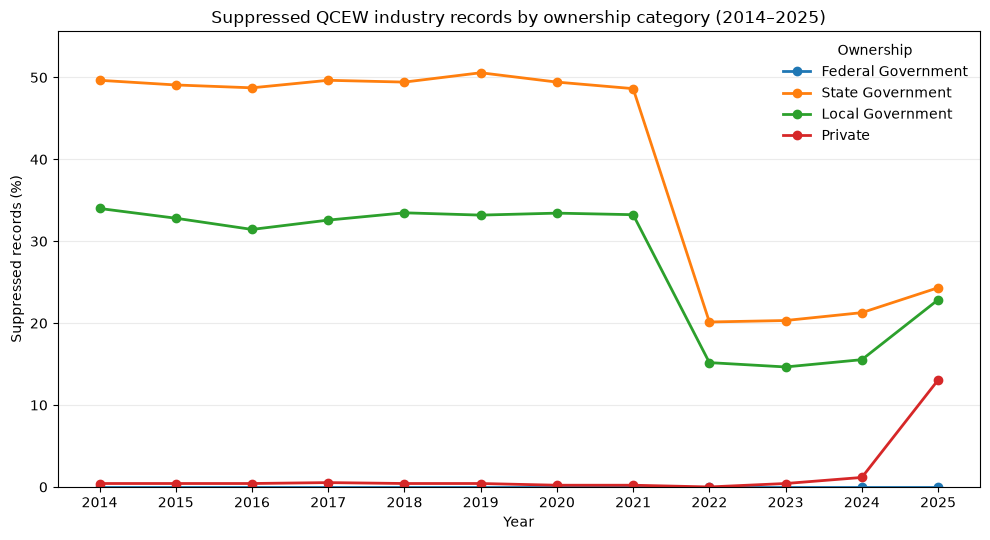

In [26]:
# Prepare disclosure-rate table for plotting
disclosure_plot = disclosure_by_ownership.pivot(
    index="year",
    columns="own_title",
    values="suppressed_pct"
).reset_index()

fig, ax = plt.subplots(figsize=(10, 5.5))

for column in [
    "Federal Government",
    "State Government",
    "Local Government",
    "Private"
]:
    ax.plot(
        disclosure_plot["year"],
        disclosure_plot[column],
        marker="o",
        linewidth=2,
        label=column
    )

ax.set(
    title="Suppressed QCEW industry records by ownership category (2014–2025)",
    xlabel="Year",
    ylabel="Suppressed records (%)"
)

ax.set_xticks(disclosure_plot["year"])
ax.set_ylim(0, disclosure_plot.drop(columns="year").max().max() * 1.1)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Ownership", frameon=False)

plt.tight_layout()

# Disclosure by ownership
fig.savefig(STATIC_DIR / "03_01_disclosure_by_ownership.png",
            dpi=300, bbox_inches="tight")
plt.show()

#### Sector-level aggregation

Industry records are aggregated across federal, state, local, and private ownership categories.

Establishment counts are summed across available records. Employment and wage totals are reported only when all contributing records have published values; otherwise, they remain missing.

Suppression indicators are retained to document data completeness. Missing ownership categories are not automatically treated as suppressed observations.


In [19]:
# Aggregate industry metrics across ownership categories
sector_keys = ["state_fips", "year", "industry_code"]

qcew_sectors = (
    qcew_sector_ownership
    .groupby(sector_keys, as_index=False)
    .agg(
        industry=("industry_title", "first"),
        establishments=("annual_avg_estabs_count", lambda x: x.sum(min_count=1)),
        employment=("annual_avg_emplvl", lambda x: x.sum(min_count=1)),
        total_annual_wages=("total_annual_wages", lambda x: x.sum(min_count=1)),
        ownership_categories=("own_code", "nunique"),
        suppressed_records=("suppressed", "sum")
    )
)

# Mark incomplete employment and wage totals
incomplete = qcew_sectors["suppressed_records"] > 0

qcew_sectors.loc[
    incomplete,
    ["employment", "total_annual_wages"]
] = float("nan")

# Derive annual pay only for complete, positive employment totals
qcew_sectors["avg_annual_pay"] = (
    qcew_sectors["total_annual_wages"] / qcew_sectors["employment"]
)

qcew_sectors["employees_per_establishment"] = (
    qcew_sectors["employment"] / qcew_sectors["establishments"]
)

qcew_sectors["employment_complete"] = (
    qcew_sectors["employment"].notna()
)

qcew_sectors = qcew_sectors.sort_values(
    sector_keys
).reset_index(drop=True)

assert not qcew_sectors.duplicated(sector_keys).any()

sector_summary = pd.DataFrame([{
    "observations": len(qcew_sectors),
    "states": qcew_sectors["state_fips"].nunique(),
    "years": qcew_sectors["year"].nunique(),
    "industries": qcew_sectors["industry_code"].nunique(),
    "complete_employment": int(qcew_sectors["employment_complete"].sum()),
    "incomplete_employment": int((~qcew_sectors["employment_complete"]).sum()),
    "missing_establishments": int(qcew_sectors["establishments"].isna().sum())
}])

display(sector_summary)


,observations,states,years,industries,complete_employment,incomplete_employment,missing_establishments
0,11400,50,12,19,7400,4000,0


#### Distribution of business establishments by industry (2025)

The distribution of business establishments across 19 major NAICS industries provides an overview of the organizational structure of the US economy.

Establishment counts are aggregated across the 50 states and all ownership categories. Unlike employment and wage totals, establishment counts remain available for records with disclosure restrictions.



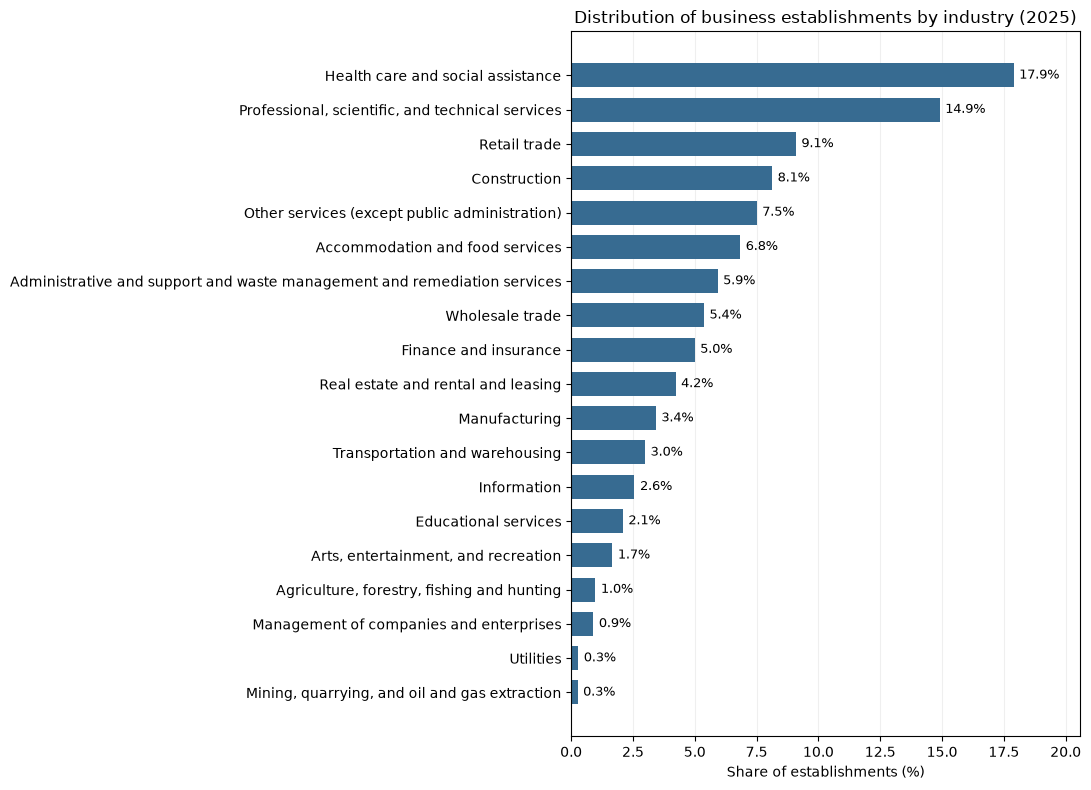

In [27]:
# Aggregate establishments across the 50 states in 2025
industry_distribution = (
    qcew_sectors.loc[qcew_sectors["year"] == 2025]
    .groupby(["industry_code", "industry"], as_index=False)["establishments"]
    .sum()
)

industry_distribution["share_pct"] = (
    100 * industry_distribution["establishments"]
    / industry_distribution["establishments"].sum()
)

industry_distribution["industry"] = (
    industry_distribution["industry"]
    .str.replace(r"^NAICS\s+[\d-]+\s+", "", regex=True)
)

industry_distribution = industry_distribution.sort_values("share_pct")

fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.barh(
    industry_distribution["industry"],
    industry_distribution["share_pct"],
    color="#376B91",
    height=0.7
)

ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9)

ax.set(
    title="Distribution of business establishments by industry (2025)",
    xlabel="Share of establishments (%)",
    ylabel=""
)

ax.set_xlim(0, industry_distribution["share_pct"].max() * 1.15)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Industry distribution
fig.savefig(STATIC_DIR / "04_02_establishments_by_industry.png",
            dpi=300, bbox_inches="tight")
plt.show()


#### Business establishments per 10,000 residents (2014–2025)

The geographic distribution of business establishments is examined relative to state population size.

$$
\text{Establishments per 10,000 residents} = \frac{\text{Annual average establishments}}{\text{Population}} \quad \times \quad 10{,}000
$$

Population figures are obtained from the cleaned BEA dataset. This normalization supports comparisons across states of different sizes, although establishments represent business locations rather than distinct firms or independent cybersecurity targets.

In [21]:
# Load population from the processed BEA dataset
bea_file = (
    PROJECT_ROOT / "data" / "processed" / "economic"
    / "bea" / "bea_state_economic_2014_2025.csv"
)

population = pd.read_csv(
    bea_file,
    dtype={"state_fips": str},
    usecols=["state_fips", "year", "population"]
)

# Normalize statewide QCEW establishments by population
qcew_map = qcew_state.merge(
    population,
    on=["state_fips", "year"],
    how="left",
    validate="one_to_one"
)

qcew_map["establishments_per_10k"] = (
    qcew_map["annual_avg_estabs_count"]
    / qcew_map["population"] * 10_000
)

assert len(qcew_map) == 600
assert qcew_map["establishments_per_10k"].notna().all()
assert (qcew_map["population"] > 0).all()


In [28]:
# Convert state FIPS codes to postal abbreviations
state_abbreviations = {
    "01": "AL", "02": "AK", "04": "AZ", "05": "AR", "06": "CA",
    "08": "CO", "09": "CT", "10": "DE", "12": "FL", "13": "GA",
    "15": "HI", "16": "ID", "17": "IL", "18": "IN", "19": "IA",
    "20": "KS", "21": "KY", "22": "LA", "23": "ME", "24": "MD",
    "25": "MA", "26": "MI", "27": "MN", "28": "MS", "29": "MO",
    "30": "MT", "31": "NE", "32": "NV", "33": "NH", "34": "NJ",
    "35": "NM", "36": "NY", "37": "NC", "38": "ND", "39": "OH",
    "40": "OK", "41": "OR", "42": "PA", "44": "RI", "45": "SC",
    "46": "SD", "47": "TN", "48": "TX", "49": "UT", "50": "VT",
    "51": "VA", "53": "WA", "54": "WV", "55": "WI", "56": "WY"
}

qcew_map["state_abbr"] = qcew_map["state_fips"].map(state_abbreviations)

fig = px.choropleth(
    qcew_map,
    locations="state_abbr",
    locationmode="USA-states",
    color="establishments_per_10k",
    animation_frame="year",
    scope="usa",
    hover_name="area_title",
    hover_data={
        "state_abbr": False,
        "year": False,
        "establishments_per_10k": ":.1f",
        "annual_avg_estabs_count": ":,.0f"
    },
    color_continuous_scale="Viridis",
    range_color=(0, qcew_map["establishments_per_10k"].max()),
    labels={
        "establishments_per_10k": "Establishments per 10,000 residents",
        "annual_avg_estabs_count": "Establishments"
    },
    title="Business establishments per 10,000 residents (2014–2025)"
)

fig.update_layout(
    height=600,
    margin=dict(l=10, r=10, t=65, b=15),
    coloraxis_colorbar=dict(title="Per 10k residents")
)
# Interactive establishments map
fig.write_html(
    INTERACTIVE_DIR / "04_03_establishments_per_10k_map.html",
    include_plotlyjs=True
)
fig.show()


#### Business establishments and employment trends (2014–2025)

Establishment counts and covered employment are compared using an index with 2014 as the base year (2014 = 100).

$$
I_t = \frac{X_t}{X_{2014}} \quad \times \quad 100
$$

Indexing enables a comparison of relative changes between indicators measured in different units. Statewide QCEW totals are used to avoid incomplete sector-level employment aggregates.

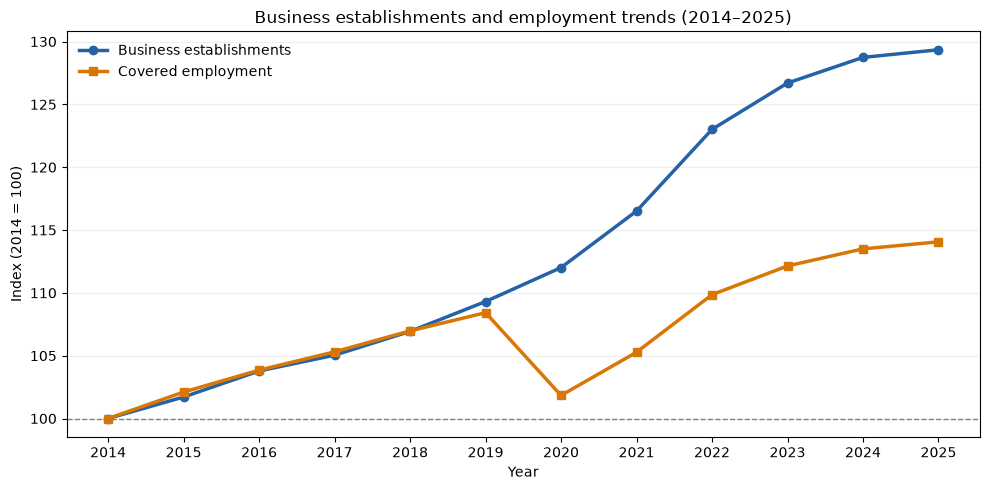

In [29]:
# Aggregate statewide QCEW totals by year
annual_activity = (
    qcew_state.groupby("year", as_index=False)
    .agg(
        establishments=("annual_avg_estabs_count", "sum"),
        employment=("annual_avg_emplvl", "sum")
    )
    .sort_values("year")
)

# Express both indicators relative to 2014
for column in ["establishments", "employment"]:
    base_value = annual_activity.loc[
        annual_activity["year"] == 2014, column
    ].iloc[0]

    annual_activity[f"{column}_index"] = (
        annual_activity[column] / base_value * 100
    )

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    annual_activity["year"],
    annual_activity["establishments_index"],
    marker="o",
    linewidth=2.5,
    color="#2563A6",
    label="Business establishments"
)

ax.plot(
    annual_activity["year"],
    annual_activity["employment_index"],
    marker="s",
    linewidth=2.5,
    color="#D97706",
    label="Covered employment"
)

ax.axhline(100, color="gray", linestyle="--", linewidth=1)

ax.set(
    title="Business establishments and employment trends (2014–2025)",
    xlabel="Year",
    ylabel="Index (2014 = 100)"
)

ax.set_xticks(annual_activity["year"])
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)

plt.tight_layout()

# Business activity trends
fig.savefig(STATIC_DIR / "04_04_business_activity_trends.png",
            dpi=300, bbox_inches="tight")
plt.show()



## 5. Validation and export

The QCEW datasets are validated and exported for integration with other economic indicators.

State-level records provide complete annual totals, while industry-level records retain information about suppressed employment and wage values. Establishment counts remain available across all selected industry observations.

The analysis covers 50 US states and 19 major NAICS industries from 2014 to 2025.


In [31]:
# Prepare state-level indicators
qcew_state_final = qcew_state[
    [
        "state_fips", "year", "area_title",
        "annual_avg_estabs_count", "annual_avg_emplvl",
        "total_annual_wages", "avg_annual_pay"
    ]
].rename(columns={
    "area_title": "state",
    "annual_avg_estabs_count": "establishments",
    "annual_avg_emplvl": "employment",
    "avg_annual_pay": "avg_annual_pay"
})

qcew_state_final["employees_per_establishment"] = (
    qcew_state_final["employment"]
    / qcew_state_final["establishments"]
)

qcew_state_final["state"] = (
    qcew_state_final["state"].str.replace(
        " -- Statewide", "", regex=False
    )
)

# Validate both datasets
assert len(qcew_state_final) == 600
assert len(qcew_sectors) == 11400

assert not qcew_state_final.duplicated(
    ["state_fips", "year"]
).any()

assert not qcew_sectors.duplicated(
    ["state_fips", "year", "industry_code"]
).any()

assert qcew_state_final.notna().all().all()
assert qcew_sectors["establishments"].notna().all()

validation_summary = pd.DataFrame([
    {
        "dataset": "State totals",
        "rows": len(qcew_state_final),
        "states": qcew_state_final["state_fips"].nunique(),
        "years": qcew_state_final["year"].nunique(),
        "missing_employment": qcew_state_final["employment"].isna().sum()
    },
    {
        "dataset": "Industry totals",
        "rows": len(qcew_sectors),
        "states": qcew_sectors["state_fips"].nunique(),
        "years": qcew_sectors["year"].nunique(),
        "missing_employment": qcew_sectors["employment"].isna().sum()
    }
])

display(validation_summary)


,dataset,rows,states,years,missing_employment
0,State totals,600,50,12,0
1,Industry totals,11400,50,12,4000


In [32]:
# Export validated QCEW datasets
OUTPUT_DIR = (
    PROJECT_ROOT / "data" / "processed" / "economic" / "bls_qcew"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

qcew_state_final.to_csv(
    OUTPUT_DIR / "qcew_state_2014_2025.csv",
    index=False
)

qcew_sectors.to_csv(
    OUTPUT_DIR / "qcew_state_industry_2014_2025.csv",
    index=False
)

print("Exported:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(f"- {path.name} ({path.stat().st_size / 1024**2:.2f} MB)")


Exported:
- qcew_state_2014_2025.csv (0.04 MB)
- qcew_state_industry_2014_2025.csv (1.12 MB)
